In [185]:
# pip install KDEpy
# pip install igraph
# pip install leidenalg

In [186]:
# These imports and path modifications are only necessary for development
import importlib

import os
import sys

module_path = os.path.abspath(os.path.join(".."))
if module_path not in sys.path:
    sys.path.append(module_path)

In [187]:
import pandas as pd
import scanpy as sc
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.sparse as sps

import BacSC.util_probe as up
import BacSC.util as ut
import BacSC.NB_est as nb
import BacSC.countsplit as cs
import BacSC.scDEED as scd
import BacSC.clustering_opt as co

import warnings

warnings.filterwarnings("ignore")

In [188]:
import visualization_functions

importlib.reload(visualization_functions)  # Force reload to avoid cache issues

from visualization_functions import (
    plot_scatter_comparison_m9f_m9,
)

In [189]:
# Set your desired path
# os.chdir("/workspaces/microsplit_DOL")
os.chdir("/Users/valentingoupille/Internship_Val_Goupille_2025/")

# Check if it worked
print("Current working directory:", os.getcwd())

os.listdir()

Current working directory: /Users/valentingoupille/Internship_Val_Goupille_2025


['reunion_intermediaire',
 '.DS_Store',
 'test',
 'rendu_stage',
 'info_internship',
 'template',
 'code',
 '.devcontainer',
 'todo.md',
 'image',
 'perspective.md',
 '.gitignore',
 'obsidian',
 '.git',
 'data']

In [190]:
### Read the data

# Adjust the data path and filename based on your folder structure
data_path = "data/anndata_objects_with_complete_metadata_filtered"
data_all = sc.read(
    data_path
    + "/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3c.h5ad"
)
data_all

AnnData object with n_obs × n_vars = 2988 × 5500
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'group', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'gene_id', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct', 'gene_pass_intersection_OD_5pct', 'gene_pass_union_OD_10pct', 'gene_pass_intersection_OD_10pct', 'gene_pass_union_OD_15pct', 'gene_pass_intersection_OD_15pct'
    uns: 'gene_metadata_added', 'gene_metadata_source', 'g

In [191]:
sc.pp.calculate_qc_metrics(data_all, inplace=True, log1p=True)
data_all.var.head()

,gene_id,final_gene_name,symbol_renamed,Gene Type,Name,Protein accession,symbol_old,locus_tag_old,n_cells_by_counts,mean_counts,...,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,gene_pass_union_OD_5pct,gene_pass_intersection_OD_5pct,gene_pass_union_OD_10pct,gene_pass_intersection_OD_10pct,gene_pass_union_OD_15pct,gene_pass_intersection_OD_15pct
gene_name,,,,,,,,,,,,,,,,,,,,,
recC,QLH64-00030,recC,False,protein-coding,exodeoxyribonuclease V subunit gamma,WHS54405.1,recC,QLH64_00030,154,0.052878,...,94.846051,158,5.068904,154,True,False,True,False,False,False
recB,QLH64-00035,recB,False,protein-coding,exodeoxyribonuclease V subunit beta,WHS54406.1,recB,QLH64_00035,114,0.038822,...,96.184739,116,4.762174,114,True,False,True,False,False,False
recD,QLH64-00040,recD,False,protein-coding,exodeoxyribonuclease V subunit alpha,WHS54407.1,recD,QLH64_00040,107,0.037149,...,96.419009,111,4.718499,107,True,False,True,False,False,False
QLH64-00045,QLH64-00045,QLH64-00045,True,protein-coding,YfiR family protein,WHS54408.1,NaN,QLH64_00045,55,0.018742,...,98.159304,56,4.043051,55,False,False,False,False,False,False
QLH64-00050,QLH64-00050,QLH64-00050,True,protein-coding,diguanylate cyclase,WHS54409.1,NaN,QLH64_00050,45,0.015395,...,98.493976,46,3.850148,45,True,False,False,False,False,False


In [192]:
data_all.var[
    "n_cells_by_counts"
].describe()  # est le nombre de ceelules dans lequel on detecte ce gene

count    5500.000000
mean      201.280182
std       359.798551
min         5.000000
25%        29.000000
50%        71.000000
75%       193.000000
max      2926.000000
Name: n_cells_by_counts, dtype: float64

In [193]:
data_all.var[
    "mean_counts"
].describe()  # mean_counts est la moyenne du nombre brut de comptes (UMIs) par gène, calculée sur toutes les cellules, sans transformation log ni normalisation.

count    5500.000000
mean        0.099817
std         0.328445
min         0.001673
25%         0.009705
50%         0.024096
75%         0.067938
max         8.741968
Name: mean_counts, dtype: float64

In [194]:
data_all.obs.head()

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,...,RepBio_suffix,group,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
barcode,,,,,,,,,,,,,,,,,,,,,
GATGAATC_AATGTTGC_CTGCTTTG,GATGAATC_AATGTTGC_CTGCTTTG,E1,G1,H11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,850,6.746412,1673,7.422971,28.810520,41.123730,56.186491,79.079498
ACTATGCA_GAGCTGAA_CTGCTTTG,ACTATGCA_GAGCTGAA_CTGCTTTG,E1,D12,B11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,852,6.748760,1542,7.341484,27.042802,39.753567,54.863813,77.172503
TATCAGCA_GACTAGTA_CTGCTTTG,TATCAGCA_GACTAGTA_CTGCTTTG,E1,C7,F1,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,828,6.720220,1499,7.313220,27.951968,39.826551,54.636424,78.118746
ACCACTGT_ATCCTGTA_CTGCTTTG,ACCACTGT_ATCCTGTA_CTGCTTTG,E1,C4,A5,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,814,6.703188,1466,7.290975,26.603001,38.267394,53.751705,78.581173
CAAGACTA_AACAACCA_CTGCTTTG,CAAGACTA_AACAACCA_CTGCTTTG,E1,B1,D11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,779,6.659294,1388,7.236339,27.665706,40.201729,56.123919,79.899135


In [195]:
for col in data_all.var.columns:
    unique_vals = data_all.var[col].unique()
    print(f"🧬 Column: {col}")
    print(f"🔢 Number of unique values: {len(unique_vals)}")
    print(f"📋 Unique values: {unique_vals}\n")

🧬 Column: gene_id
🔢 Number of unique values: 5500
📋 Unique values: ['QLH64-00030' 'QLH64-00035' 'QLH64-00040' ... 'QLH64-31235' 'QLH64-31240'
 'QLH64-31245']

🧬 Column: final_gene_name
🔢 Number of unique values: 5500
📋 Unique values: ['recC' 'recB' 'recD' ... 'QLH64-31235' 'QLH64-31240' 'QLH64-31245']

🧬 Column: symbol_renamed
🔢 Number of unique values: 2
📋 Unique values: [False  True]

🧬 Column: Gene Type
🔢 Number of unique values: 1
📋 Unique values: ['protein-coding']
Categories (1, object): ['protein-coding']

🧬 Column: Name
🔢 Number of unique values: 2961
📋 Unique values: ['exodeoxyribonuclease V subunit gamma', 'exodeoxyribonuclease V subunit beta', 'exodeoxyribonuclease V subunit alpha', 'YfiR family protein', 'diguanylate cyclase', ..., 'TonB C-terminal domain-containing protein', 'DNA-binding protein', 'endonuclease', 'nucleotidyl transferase AbiEii/AbiGii toxin f..., 'DUF6088 family protein']
Length: 2961
Categories (2961, object): ['1,4-alpha-glucan branching protein GlgB', '

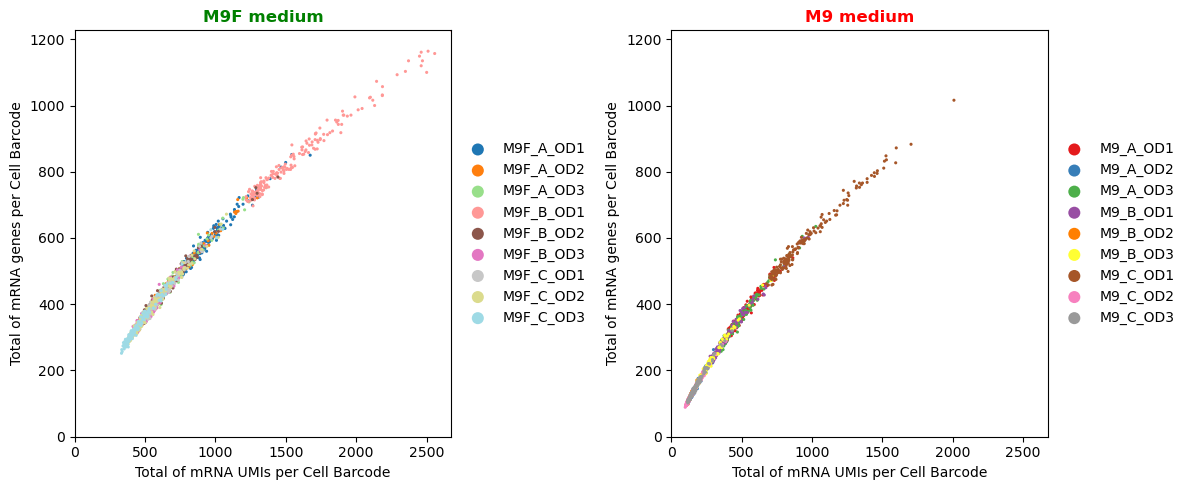

In [196]:
# Create scatter plots comparing M9F vs M9 culture mediums
plot_scatter_comparison_m9f_m9(
    data_all,
    x_column="total_counts",
    y_column="n_genes_by_counts",
    color_column="OD",
    x_label="Total of mRNA UMIs per Cell Barcode",
    y_label="Total of mRNA genes per Cell Barcode",
    point_size=20,
    figsize=(12, 5),
    title_suffix="",
)

📊 SPARSITY ANALYSIS


📈 Data dimensions: 2,988 cells × 5,500 genes
🔢 Total number of values: 16,434,000
🕳️  Number of zeros: 15,326,959
📊 Sparsity percentage: 93.3%

🧬 Expressed genes per cell:
   - Mean: 370
   - Median: 357
   - Min-Max: 89-1227

🔬 Cells expressing each gene:
   - Mean: 201
   - Median: 71
   - Min-Max: 5-2926

💡 WHY ARE THE MATRICES SPARSE?
   🧬 Biological: Each cell only expresses a subset of genes
   🔬 Technical: Dropout, capture efficiency, detection threshold
   💾 Practical: Memory efficiency (storing only non-zeros)
   ⚡ Performance: Faster computations by skipping zeros


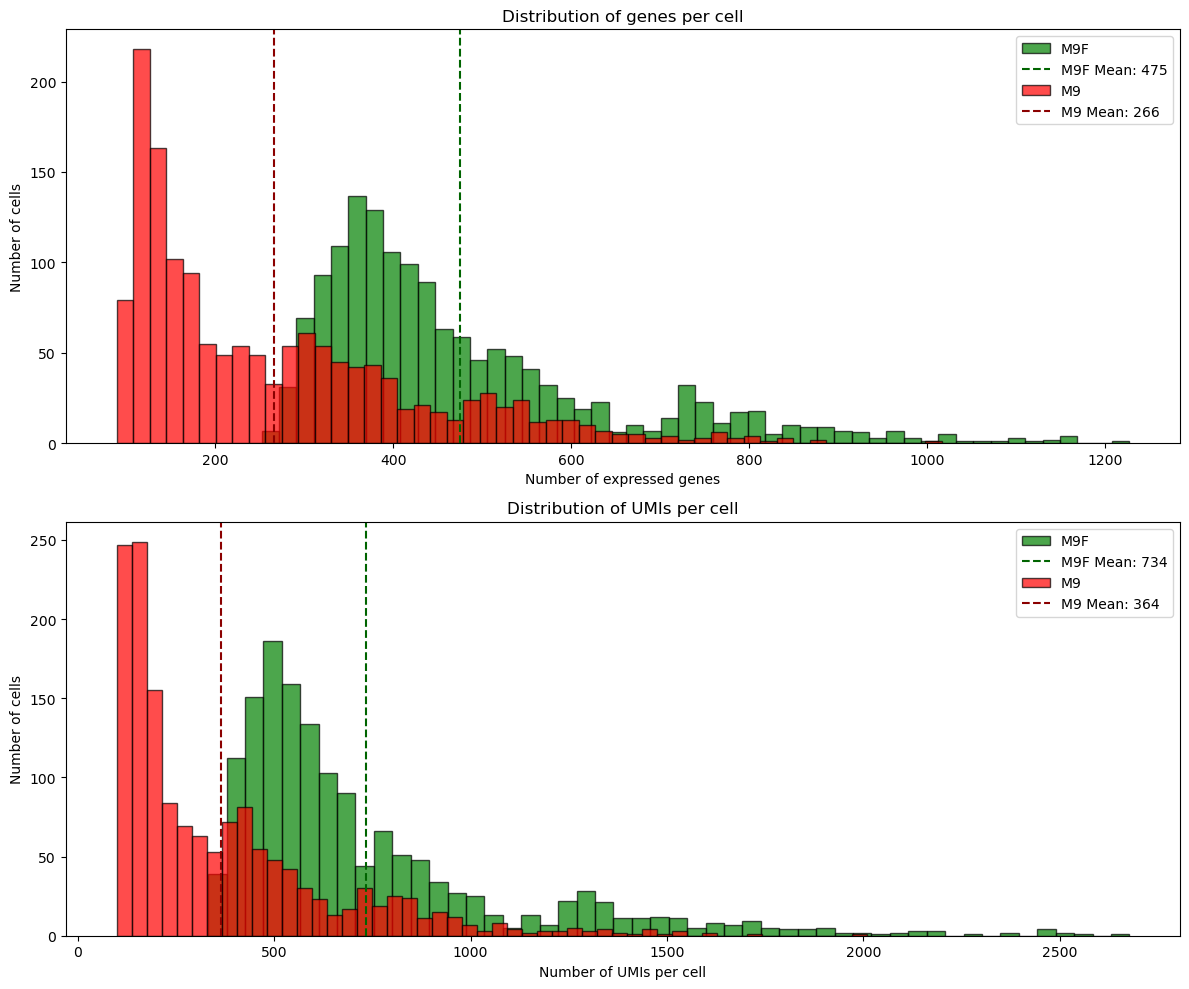

In [197]:
# Sparsity analysis of the data
print("=" * 60)
print("📊 SPARSITY ANALYSIS")
print("=" * 60)

# Calculate sparsity statistics
total_values = data_all.n_obs * data_all.n_vars
zero_values = (data_all.X == 0).sum()
sparsity_percentage = (zero_values / total_values) * 100

print(f"📈 Data dimensions: {data_all.n_obs:,} cells × {data_all.n_vars:,} genes")
print(f"🔢 Total number of values: {total_values:,}")
print(f"🕳️  Number of zeros: {zero_values:,}")
print(f"📊 Sparsity percentage: {sparsity_percentage:.1f}%")

# Analysis per cell
genes_per_cell = np.asarray((data_all.X > 0).sum(axis=1)).squeeze()
print(f"\n🧬 Expressed genes per cell:")
print(f"   - Mean: {genes_per_cell.mean():.0f}")
print(f"   - Median: {np.median(genes_per_cell):.0f}")
print(f"   - Min-Max: {genes_per_cell.min()}-{genes_per_cell.max()}")

# Analysis per gene
cells_per_gene = np.asarray((data_all.X > 0).sum(axis=0)).squeeze()
print(f"\n🔬 Cells expressing each gene:")
print(f"   - Mean: {cells_per_gene.mean():.0f}")
print(f"   - Median: {np.median(cells_per_gene):.0f}")
print(f"   - Min-Max: {cells_per_gene.min()}-{cells_per_gene.max()}")


# Distribution visualization - Number of genes per cell
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Histogram of genes per cell - M9F (left, green)
m9f_mask = data_all.obs["OD"].str.contains("M9F")
genes_per_cell_m9f = genes_per_cell[m9f_mask]
ax1.hist(
    genes_per_cell_m9f,
    bins=50,
    alpha=0.7,
    color="green",
    edgecolor="black",
    label="M9F",
)
ax1.axvline(
    genes_per_cell_m9f.mean(),
    color="darkgreen",
    linestyle="--",
    label=f"M9F Mean: {genes_per_cell_m9f.mean():.0f}",
)

# Histogram of genes per cell - M9 (right, red)
m9_mask = ~data_all.obs["OD"].str.contains("M9F")
genes_per_cell_m9 = genes_per_cell[m9_mask]
ax1.hist(
    genes_per_cell_m9, bins=50, alpha=0.7, color="red", edgecolor="black", label="M9"
)
ax1.axvline(
    genes_per_cell_m9.mean(),
    color="darkred",
    linestyle="--",
    label=f"M9 Mean: {genes_per_cell_m9.mean():.0f}",
)

ax1.set_xlabel("Number of expressed genes")
ax1.set_ylabel("Number of cells")
ax1.set_title("Distribution of genes per cell")
ax1.legend()

# Distribution visualization - Number of UMIs per cell
total_counts_m9f = data_all[m9f_mask].obs["total_counts"]
total_counts_m9 = data_all[m9_mask].obs["total_counts"]

ax2.hist(
    total_counts_m9f, bins=50, alpha=0.7, color="green", edgecolor="black", label="M9F"
)
ax2.axvline(
    total_counts_m9f.mean(),
    color="darkgreen",
    linestyle="--",
    label=f"M9F Mean: {total_counts_m9f.mean():.0f}",
)

ax2.hist(
    total_counts_m9, bins=50, alpha=0.7, color="red", edgecolor="black", label="M9"
)
ax2.axvline(
    total_counts_m9.mean(),
    color="darkred",
    linestyle="--",
    label=f"M9 Mean: {total_counts_m9.mean():.0f}",
)

ax2.set_xlabel("Number of UMIs per cell")
ax2.set_ylabel("Number of cells")
ax2.set_title("Distribution of UMIs per cell")
ax2.legend()

plt.tight_layout()

print(f"\n💡 WHY ARE THE MATRICES SPARSE?")
print(f"   🧬 Biological: Each cell only expresses a subset of genes")
print(f"   🔬 Technical: Dropout, capture efficiency, detection threshold")
print(f"   💾 Practical: Memory efficiency (storing only non-zeros)")
print(f"   ⚡ Performance: Faster computations by skipping zeros")

In [198]:
data_gene = data_all.copy()
data_gene.layers["counts"] = data_gene.X.copy()

In [199]:
# Vérifier les valeurs infinies et NaN
print("Valeurs infinies:", np.isinf(data_gene.layers["counts"].toarray()).sum())
print("Valeurs NaN:", np.isnan(data_gene.layers["counts"].toarray()).sum())
print("Valeurs nulles:", (data_gene.layers["counts"].toarray() == 0).sum())

Valeurs infinies: 0
Valeurs NaN: 0
Valeurs nulles: 15326959


In [200]:
# Filtrage strict des gènes pour éviter les problèmes dans SCTransform
import numpy as np

print("=== FILTRAGE STRICT DES GÈNES ===")

# 1. Analyser les données actuelles
print(f"1. Données initiales:")
print(f"   - Forme: {data_gene.shape}")
print(f"   - Gènes: {data_gene.n_vars}")
print(f"   - Cellules: {data_gene.n_obs}")

# 2. Calculer les statistiques par gène
gene_sums = np.array(data_gene.X.sum(axis=0)).flatten()
gene_means = np.array(data_gene.X.mean(axis=0)).flatten()
gene_nonzero = np.array((data_gene.X > 0).sum(axis=0)).flatten()

print(f"\n2. Statistiques par gène:")
print(f"   - Somme min: {gene_sums.min()}")
print(f"   - Somme max: {gene_sums.max()}")
print(f"   - Somme moyenne: {gene_sums.mean():.2f}")
print(f"   - Somme médiane: {np.median(gene_sums):.2f}")

print(f"\n   - Moyenne min: {gene_means.min()}")
print(f"   - Moyenne max: {gene_means.max()}")
print(f"   - Moyenne moyenne: {gene_means.mean():.4f}")

print(f"\n   - Cellules non-nulles min: {gene_nonzero.min()}")
print(f"   - Cellules non-nulles max: {gene_nonzero.max()}")
print(f"   - Cellules non-nulles moyenne: {gene_nonzero.mean():.2f}")

# 3. Définir les critères de filtrage strict
min_total_counts = 20  # Au moins 20 comptages totaux par gène
min_cells_expressed = 5  # Exprimé dans au moins 5 cellules
min_mean_expression = 0.1  # Moyenne d'expression d'au moins 0.1

print(f"\n3. Critères de filtrage:")
print(f"   - Comptages totaux minimum: {min_total_counts}")
print(f"   - Cellules exprimées minimum: {min_cells_expressed}")
print(f"   - Moyenne d'expression minimum: {min_mean_expression}")

# 4. Appliquer le filtrage
mask_total_counts = gene_sums >= min_total_counts
mask_cells_expressed = gene_nonzero >= min_cells_expressed
mask_mean_expression = gene_means >= min_mean_expression

# Combiner tous les critères
mask_combined = mask_total_counts & mask_cells_expressed & mask_mean_expression

print(f"\n4. Résultats du filtrage:")
print(f"   - Gènes passant critère comptages totaux: {mask_total_counts.sum()}")
print(f"   - Gènes passant critère cellules exprimées: {mask_cells_expressed.sum()}")
print(f"   - Gènes passant critère moyenne expression: {mask_mean_expression.sum()}")
print(f"   - Gènes passant TOUS les critères: {mask_combined.sum()}")

# 5. Créer le dataset filtré
data_gene_strict = data_gene[:, mask_combined].copy()

print(f"\n5. Dataset filtré:")
print(f"   - Forme: {data_gene_strict.shape}")
print(f"   - Gènes retenus: {data_gene_strict.n_vars}")
print(
    f"   - Pourcentage de gènes retenus: {data_gene_strict.n_vars/data_gene.n_vars*100:.1f}%"
)

# 6. Vérifier les données filtrées
gene_sums_filtered = np.array(data_gene_strict.X.sum(axis=0)).flatten()
gene_means_filtered = np.array(data_gene_strict.X.mean(axis=0)).flatten()
gene_nonzero_filtered = np.array((data_gene_strict.X > 0).sum(axis=0)).flatten()

print(f"\n6. Statistiques après filtrage:")
print(f"   - Somme min: {gene_sums_filtered.min()}")
print(f"   - Somme moyenne: {gene_sums_filtered.mean():.2f}")
print(f"   - Moyenne min: {gene_means_filtered.min()}")
print(f"   - Moyenne moyenne: {gene_means_filtered.mean():.4f}")
print(f"   - Cellules non-nulles min: {gene_nonzero_filtered.min()}")
print(f"   - Cellules non-nulles moyenne: {gene_nonzero_filtered.mean():.2f}")

# 7. Vérifier qu'il n'y a plus de valeurs problématiques
print(f"\n7. Vérification des valeurs problématiques:")
X_filtered = (
    data_gene_strict.X.toarray()
    if hasattr(data_gene_strict.X, "toarray")
    else data_gene_strict.X
)
print(f"   - Valeurs NaN: {np.isnan(X_filtered).sum()}")
print(f"   - Valeurs infinies: {np.isinf(X_filtered).sum()}")
print(f"   - Valeurs négatives: {(X_filtered < 0).sum()}")

print("=== FILTRAGE TERMINÉ ===")

=== FILTRAGE STRICT DES GÈNES ===
1. Données initiales:
   - Forme: (2988, 5500)
   - Gènes: 5500
   - Cellules: 2988

2. Statistiques par gène:
   - Somme min: 5
   - Somme max: 26121
   - Somme moyenne: 298.25
   - Somme médiane: 72.00

   - Moyenne min: 0.0016733601070950468
   - Moyenne max: 8.741967871485944
   - Moyenne moyenne: 0.0998

   - Cellules non-nulles min: 5
   - Cellules non-nulles max: 2926
   - Cellules non-nulles moyenne: 201.28

3. Critères de filtrage:
   - Comptages totaux minimum: 20
   - Cellules exprimées minimum: 5
   - Moyenne d'expression minimum: 0.1

4. Résultats du filtrage:
   - Gènes passant critère comptages totaux: 4589
   - Gènes passant critère cellules exprimées: 5500
   - Gènes passant critère moyenne expression: 1013
   - Gènes passant TOUS les critères: 1013

5. Dataset filtré:
   - Forme: (2988, 1013)
   - Gènes retenus: 1013
   - Pourcentage de gènes retenus: 18.4%

6. Statistiques après filtrage:
   - Somme min: 299
   - Somme moyenne: 1277.

In [ ]:
adata = data_gene.copy()
# Saving count data
adata.layers["counts"] = adata.X.copy()

In [202]:
# Normalize to median total counts and save in 'normalized' layer
adata.layers["normalized"] = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, layer="normalized", copy=False)  # target_sum=1000

# Log transform normalized data and save in 'log1p' layer
adata.layers["log1p"] = adata.layers["normalized"].copy()
sc.pp.log1p(adata, layer="log1p", copy=False)

# Keep normalized and log-transformed data in main matrix
adata.X = adata.layers["log1p"].copy()

In [203]:
adata.layers

Layers with keys: counts, normalized, log1p

In [204]:
adata.obs

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,...,RepBio_suffix,group,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
barcode,,,,,,,,,,,,,,,,,,,,,
GATGAATC_AATGTTGC_CTGCTTTG,GATGAATC_AATGTTGC_CTGCTTTG,E1,G1,H11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,850,6.746412,1673,7.422971,28.810520,41.123730,56.186491,79.079498
ACTATGCA_GAGCTGAA_CTGCTTTG,ACTATGCA_GAGCTGAA_CTGCTTTG,E1,D12,B11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,852,6.748760,1542,7.341484,27.042802,39.753567,54.863813,77.172503
TATCAGCA_GACTAGTA_CTGCTTTG,TATCAGCA_GACTAGTA_CTGCTTTG,E1,C7,F1,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,828,6.720220,1499,7.313220,27.951968,39.826551,54.636424,78.118746
ACCACTGT_ATCCTGTA_CTGCTTTG,ACCACTGT_ATCCTGTA_CTGCTTTG,E1,C4,A5,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,814,6.703188,1466,7.290975,26.603001,38.267394,53.751705,78.581173
CAAGACTA_AACAACCA_CTGCTTTG,CAAGACTA_AACAACCA_CTGCTTTG,E1,B1,D11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,779,6.659294,1388,7.236339,27.665706,40.201729,56.123919,79.899135
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CTGAGCCA_AATCCGTC_ATTCATGG,CTGAGCCA_AATCCGTC_ATTCATGG,A9,F12,D8,M9,M9_C,M9_C_OD3,M9_C_OD3_1,OD3,0.8,...,C,M9_sampling_t3,109,4.700480,122,4.812184,51.639344,92.622951,100.000000,100.000000
ACGCTCGA_AAGACGGA_ATCGCATA,ACGCTCGA_AAGACGGA_ATCGCATA,A11,B4,B9,M9,M9_C,M9_C_OD3,M9_C_OD3_5,OD3,0.8,...,C,M9_sampling_t3,110,4.709530,120,4.795791,50.000000,91.666667,100.000000,100.000000
CGGATTGC_CACCTTAC_ACGCCGGC,CGGATTGC_CACCTTAC_ACGCCGGC,B9,G12,H6,M9,M9_C,M9_C_OD3,M9_C_OD3_2,OD3,0.8,...,C,M9_sampling_t3,108,4.691348,122,4.812184,52.459016,93.442623,100.000000,100.000000


In [ ]:
# Identify highly variable genes using log1p normalized data
# This helps focus on genes with high cell-to-cell variation
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=500,  # batch_key="sample"
)

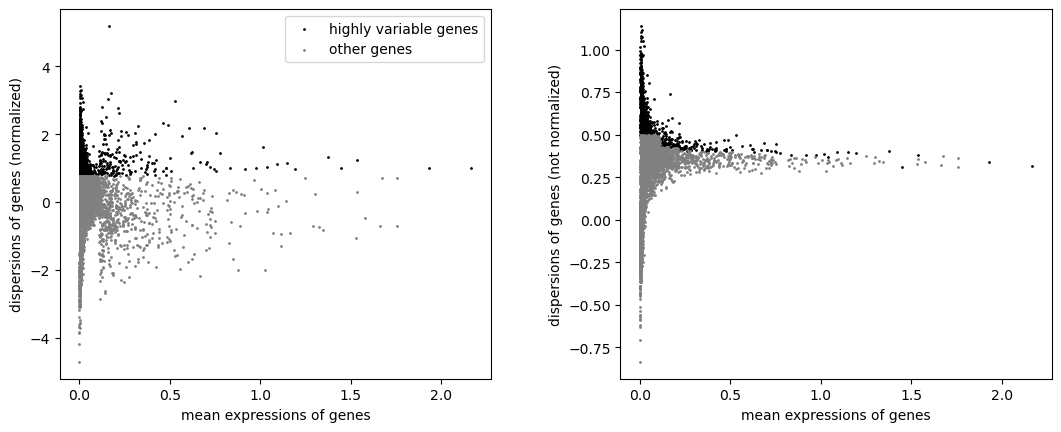

In [206]:
sc.pl.highly_variable_genes(adata)

In [207]:
# Scale data and save in 'scaled' layer
adata.layers["scaled"] = adata.layers["log1p"].copy()
sc.pp.scale(adata, max_value=10, zero_center=True, layer="scaled", copy=False)
# save it in the main matrix
adata.X = adata.layers["scaled"].copy()

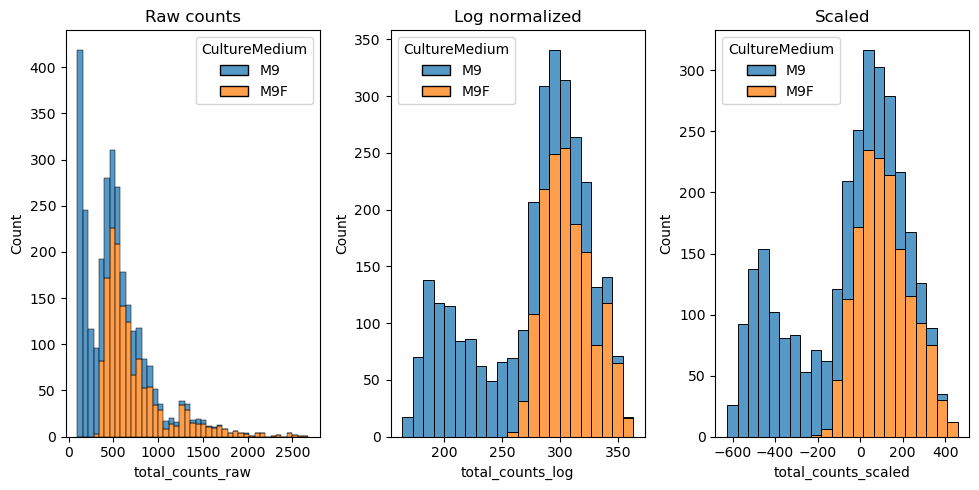

In [208]:
fig, axes = plt.subplots(1, 3, figsize=(10, 5))

# Plot raw counts data from counts layer
adata.obs["total_counts_raw"] = adata.layers["counts"].sum(1)
p1 = sns.histplot(
    data=adata.obs,
    x="total_counts_raw",
    hue="CultureMedium",
    kde=False,
    ax=axes[0],
    multiple="stack",
)
axes[0].set_title("Raw counts")

# Get log normalized data from layers
adata.obs["total_counts_log"] = adata.layers["log1p"].sum(1)
p2 = sns.histplot(
    data=adata.obs,
    x="total_counts_log",
    hue="CultureMedium",
    kde=False,
    ax=axes[1],
    multiple="stack",
)
axes[1].set_title("Log normalized")

# Get scaled data from scaled layer
adata.obs["total_counts_scaled"] = adata.layers["scaled"].sum(1)
p3 = sns.histplot(
    data=adata.obs,
    x="total_counts_scaled",
    hue="CultureMedium",
    kde=False,
    ax=axes[2],
    multiple="stack",
)
axes[2].set_title("Scaled")
plt.tight_layout()
plt.show()

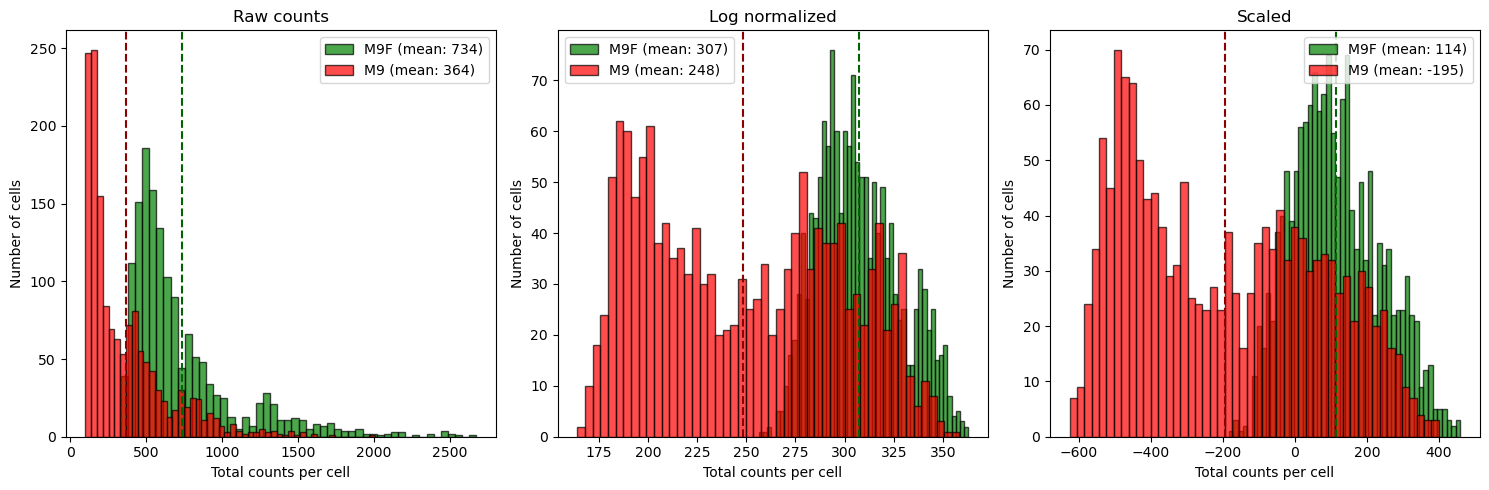

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Define masks
m9f_mask = adata.obs["CultureMedium"].str.contains("M9F")
m9_mask = ~m9f_mask

# Define colors
colors = {"M9F": "green", "M9": "red"}
mean_line_colors = {"M9F": "darkgreen", "M9": "darkred"}


# Plot function
def plot_hist(ax, values, title):
    m9f_vals = values[m9f_mask]
    m9_vals = values[m9_mask]

    # M9F
    ax.hist(
        m9f_vals,
        bins=50,
        alpha=0.7,
        color=colors["M9F"],
        edgecolor="black",
        label=f"M9F (mean: {m9f_vals.mean():.0f})",
    )
    ax.axvline(m9f_vals.mean(), color=mean_line_colors["M9F"], linestyle="--")

    # M9
    ax.hist(
        m9_vals,
        bins=50,
        alpha=0.7,
        color=colors["M9"],
        edgecolor="black",
        label=f"M9 (mean: {m9_vals.mean():.0f})",
    )
    ax.axvline(m9_vals.mean(), color=mean_line_colors["M9"], linestyle="--")

    ax.set_title(title)
    ax.set_xlabel("Total counts per cell")
    ax.set_ylabel("Number of cells")
    ax.legend()


# Raw counts
adata.obs["total_counts_raw"] = adata.layers["counts"].sum(1)
plot_hist(axes[0], adata.obs["total_counts_raw"], "Raw counts")

# Log normalized
adata.obs["total_counts_log"] = adata.layers["log1p"].sum(1)
plot_hist(axes[1], adata.obs["total_counts_log"], "Log normalized")

# Scaled
adata.obs["total_counts_scaled"] = adata.layers["scaled"].sum(1)
plot_hist(axes[2], adata.obs["total_counts_scaled"], "Scaled")

plt.tight_layout()
plt.show()

In [ ]:
# Filtrage strict des gènes pour éviter les problèmes dans SCTransform
import numpy as np

print("=== FILTRAGE STRICT DES GÈNES ===")

# 1. Analyser les données actuelles
print(f"1. Données initiales:")
print(f"   - Forme: {data_gene.shape}")
print(f"   - Gènes: {data_gene.n_vars}")
print(f"   - Cellules: {data_gene.n_obs}")

# 2. Calculer les statistiques par gène
gene_sums = np.array(data_gene.X.sum(axis=0)).flatten()
gene_means = np.array(data_gene.X.mean(axis=0)).flatten()
gene_nonzero = np.array((data_gene.X > 0).sum(axis=0)).flatten()

print(f"\n2. Statistiques par gène:")
print(f"   - Somme min: {gene_sums.min()}")
print(f"   - Somme max: {gene_sums.max()}")
print(f"   - Somme moyenne: {gene_sums.mean():.2f}")
print(f"   - Somme médiane: {np.median(gene_sums):.2f}")

print(f"\n   - Moyenne min: {gene_means.min()}")
print(f"   - Moyenne max: {gene_means.max()}")
print(f"   - Moyenne moyenne: {gene_means.mean():.4f}")

print(f"\n   - Cellules non-nulles min: {gene_nonzero.min()}")
print(f"   - Cellules non-nulles max: {gene_nonzero.max()}")
print(f"   - Cellules non-nulles moyenne: {gene_nonzero.mean():.2f}")

# 3. Définir les critères de filtrage strict
min_total_counts = 20  # Au moins 20 comptages totaux par gène
min_cells_expressed = 5  # Exprimé dans au moins 5 cellules
min_mean_expression = 0.1  # Moyenne d'expression d'au moins 0.1

print(f"\n3. Critères de filtrage:")
print(f"   - Comptages totaux minimum: {min_total_counts}")
print(f"   - Cellules exprimées minimum: {min_cells_expressed}")
print(f"   - Moyenne d'expression minimum: {min_mean_expression}")

# 4. Appliquer le filtrage
mask_total_counts = gene_sums >= min_total_counts
mask_cells_expressed = gene_nonzero >= min_cells_expressed
mask_mean_expression = gene_means >= min_mean_expression

# Combiner tous les critères
mask_combined = mask_total_counts & mask_cells_expressed & mask_mean_expression

print(f"\n4. Résultats du filtrage:")
print(f"   - Gènes passant critère comptages totaux: {mask_total_counts.sum()}")
print(f"   - Gènes passant critère cellules exprimées: {mask_cells_expressed.sum()}")
print(f"   - Gènes passant critère moyenne expression: {mask_mean_expression.sum()}")
print(f"   - Gènes passant TOUS les critères: {mask_combined.sum()}")

# 5. Créer le dataset filtré
data_gene_strict = data_gene[:, mask_combined].copy()

print(f"\n5. Dataset filtré:")
print(f"   - Forme: {data_gene_strict.shape}")
print(f"   - Gènes retenus: {data_gene_strict.n_vars}")
print(
    f"   - Pourcentage de gènes retenus: {data_gene_strict.n_vars/data_gene.n_vars*100:.1f}%"
)

# 6. Vérifier les données filtrées
gene_sums_filtered = np.array(data_gene_strict.X.sum(axis=0)).flatten()
gene_means_filtered = np.array(data_gene_strict.X.mean(axis=0)).flatten()
gene_nonzero_filtered = np.array((data_gene_strict.X > 0).sum(axis=0)).flatten()

print(f"\n6. Statistiques après filtrage:")
print(f"   - Somme min: {gene_sums_filtered.min()}")
print(f"   - Somme moyenne: {gene_sums_filtered.mean():.2f}")
print(f"   - Moyenne min: {gene_means_filtered.min()}")
print(f"   - Moyenne moyenne: {gene_means_filtered.mean():.4f}")
print(f"   - Cellules non-nulles min: {gene_nonzero_filtered.min()}")
print(f"   - Cellules non-nulles moyenne: {gene_nonzero_filtered.mean():.2f}")

# 7. Vérifier qu'il n'y a plus de valeurs problématiques
print(f"\n7. Vérification des valeurs problématiques:")
X_filtered = (
    data_gene_strict.X.toarray()
    if hasattr(data_gene_strict.X, "toarray")
    else data_gene_strict.X
)
print(f"   - Valeurs NaN: {np.isnan(X_filtered).sum()}")
print(f"   - Valeurs infinies: {np.isinf(X_filtered).sum()}")
print(f"   - Valeurs négatives: {(X_filtered < 0).sum()}")

print("=== FILTRAGE TERMINÉ ===")

=== FILTRAGE STRICT DES GÈNES ===
1. Données initiales:
   - Forme: (2988, 5500)
   - Gènes: 5500
   - Cellules: 2988

2. Statistiques par gène:
   - Somme min: 5
   - Somme max: 26121
   - Somme moyenne: 298.25
   - Somme médiane: 72.00

   - Moyenne min: 0.0016733601070950468
   - Moyenne max: 8.741967871485944
   - Moyenne moyenne: 0.0998

   - Cellules non-nulles min: 5
   - Cellules non-nulles max: 2926
   - Cellules non-nulles moyenne: 201.28

3. Critères de filtrage:
   - Comptages totaux minimum: 20
   - Cellules exprimées minimum: 5
   - Moyenne d'expression minimum: 0.1

4. Résultats du filtrage:
   - Gènes passant critère comptages totaux: 4589
   - Gènes passant critère cellules exprimées: 5500
   - Gènes passant critère moyenne expression: 1013
   - Gènes passant TOUS les critères: 1013

5. Dataset filtré:
   - Forme: (2988, 1013)
   - Gènes retenus: 1013
   - Pourcentage de gènes retenus: 18.4%

6. Statistiques après filtrage:
   - Somme min: 299
   - Somme moyenne: 1277.

In [ ]:
# Filtrage strict des gènes pour éviter les problèmes dans SCTransform
import numpy as np

print("=== FILTRAGE STRICT DES GÈNES ===")

# 1. Analyser les données actuelles
print(f"1. Données initiales:")
print(f"   - Forme: {data_gene.shape}")
print(f"   - Gènes: {data_gene.n_vars}")
print(f"   - Cellules: {data_gene.n_obs}")

# 2. Calculer les statistiques par gène
gene_sums = np.array(data_gene.X.sum(axis=0)).flatten()
gene_means = np.array(data_gene.X.mean(axis=0)).flatten()
gene_nonzero = np.array((data_gene.X > 0).sum(axis=0)).flatten()

print(f"\n2. Statistiques par gène:")
print(f"   - Somme min: {gene_sums.min()}")
print(f"   - Somme max: {gene_sums.max()}")
print(f"   - Somme moyenne: {gene_sums.mean():.2f}")
print(f"   - Somme médiane: {np.median(gene_sums):.2f}")

print(f"\n   - Moyenne min: {gene_means.min()}")
print(f"   - Moyenne max: {gene_means.max()}")
print(f"   - Moyenne moyenne: {gene_means.mean():.4f}")

print(f"\n   - Cellules non-nulles min: {gene_nonzero.min()}")
print(f"   - Cellules non-nulles max: {gene_nonzero.max()}")
print(f"   - Cellules non-nulles moyenne: {gene_nonzero.mean():.2f}")

# 3. Définir les critères de filtrage strict
min_total_counts = 20  # Au moins 20 comptages totaux par gène
min_cells_expressed = 5  # Exprimé dans au moins 5 cellules
min_mean_expression = 0.1  # Moyenne d'expression d'au moins 0.1

print(f"\n3. Critères de filtrage:")
print(f"   - Comptages totaux minimum: {min_total_counts}")
print(f"   - Cellules exprimées minimum: {min_cells_expressed}")
print(f"   - Moyenne d'expression minimum: {min_mean_expression}")

# 4. Appliquer le filtrage
mask_total_counts = gene_sums >= min_total_counts
mask_cells_expressed = gene_nonzero >= min_cells_expressed
mask_mean_expression = gene_means >= min_mean_expression

# Combiner tous les critères
mask_combined = mask_total_counts & mask_cells_expressed & mask_mean_expression

print(f"\n4. Résultats du filtrage:")
print(f"   - Gènes passant critère comptages totaux: {mask_total_counts.sum()}")
print(f"   - Gènes passant critère cellules exprimées: {mask_cells_expressed.sum()}")
print(f"   - Gènes passant critère moyenne expression: {mask_mean_expression.sum()}")
print(f"   - Gènes passant TOUS les critères: {mask_combined.sum()}")

# 5. Créer le dataset filtré
data_gene_strict = data_gene[:, mask_combined].copy()

print(f"\n5. Dataset filtré:")
print(f"   - Forme: {data_gene_strict.shape}")
print(f"   - Gènes retenus: {data_gene_strict.n_vars}")
print(
    f"   - Pourcentage de gènes retenus: {data_gene_strict.n_vars/data_gene.n_vars*100:.1f}%"
)

# 6. Vérifier les données filtrées
gene_sums_filtered = np.array(data_gene_strict.X.sum(axis=0)).flatten()
gene_means_filtered = np.array(data_gene_strict.X.mean(axis=0)).flatten()
gene_nonzero_filtered = np.array((data_gene_strict.X > 0).sum(axis=0)).flatten()

print(f"\n6. Statistiques après filtrage:")
print(f"   - Somme min: {gene_sums_filtered.min()}")
print(f"   - Somme moyenne: {gene_sums_filtered.mean():.2f}")
print(f"   - Moyenne min: {gene_means_filtered.min()}")
print(f"   - Moyenne moyenne: {gene_means_filtered.mean():.4f}")
print(f"   - Cellules non-nulles min: {gene_nonzero_filtered.min()}")
print(f"   - Cellules non-nulles moyenne: {gene_nonzero_filtered.mean():.2f}")

# 7. Vérifier qu'il n'y a plus de valeurs problématiques
print(f"\n7. Vérification des valeurs problématiques:")
X_filtered = (
    data_gene_strict.X.toarray()
    if hasattr(data_gene_strict.X, "toarray")
    else data_gene_strict.X
)
print(f"   - Valeurs NaN: {np.isnan(X_filtered).sum()}")
print(f"   - Valeurs infinies: {np.isinf(X_filtered).sum()}")
print(f"   - Valeurs négatives: {(X_filtered < 0).sum()}")

print("=== FILTRAGE TERMINÉ ===")

=== FILTRAGE STRICT DES GÈNES ===
1. Données initiales:
   - Forme: (2988, 5500)
   - Gènes: 5500
   - Cellules: 2988

2. Statistiques par gène:
   - Somme min: 5
   - Somme max: 26121
   - Somme moyenne: 298.25
   - Somme médiane: 72.00

   - Moyenne min: 0.0016733601070950468
   - Moyenne max: 8.741967871485944
   - Moyenne moyenne: 0.0998

   - Cellules non-nulles min: 5
   - Cellules non-nulles max: 2926
   - Cellules non-nulles moyenne: 201.28

3. Critères de filtrage:
   - Comptages totaux minimum: 20
   - Cellules exprimées minimum: 5
   - Moyenne d'expression minimum: 0.1

4. Résultats du filtrage:
   - Gènes passant critère comptages totaux: 4589
   - Gènes passant critère cellules exprimées: 5500
   - Gènes passant critère moyenne expression: 1013
   - Gènes passant TOUS les critères: 1013

5. Dataset filtré:
   - Forme: (2988, 1013)
   - Gènes retenus: 1013
   - Pourcentage de gènes retenus: 18.4%

6. Statistiques après filtrage:
   - Somme min: 299
   - Somme moyenne: 1277.

In [209]:
sc.tl.pca(adata)

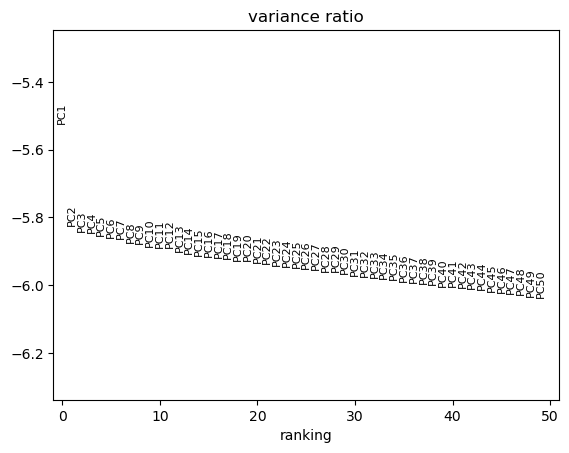

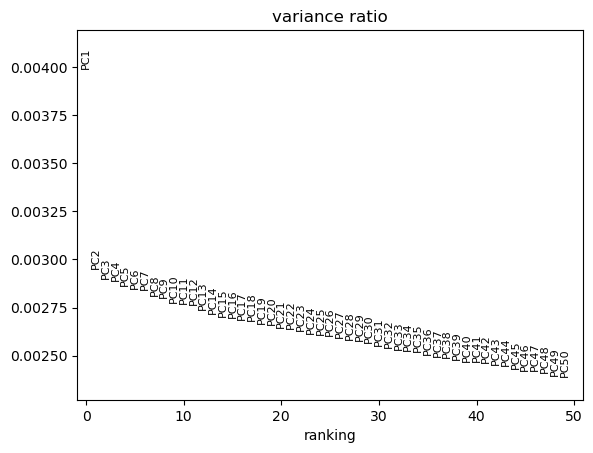

In [210]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=False)

In [211]:
adata

AnnData object with n_obs × n_vars = 2988 × 5500
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'group', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_raw', 'total_counts_log', 'total_counts_scaled'
    var: 'gene_id', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct', 'gene_pass_intersection_OD_5pct', 'gene_pass_union_OD_10pct', 'gene_pass_intersection_OD_10pct', 'gene_pass_union_OD_15pct', 'gene_pass_intersection_OD_15

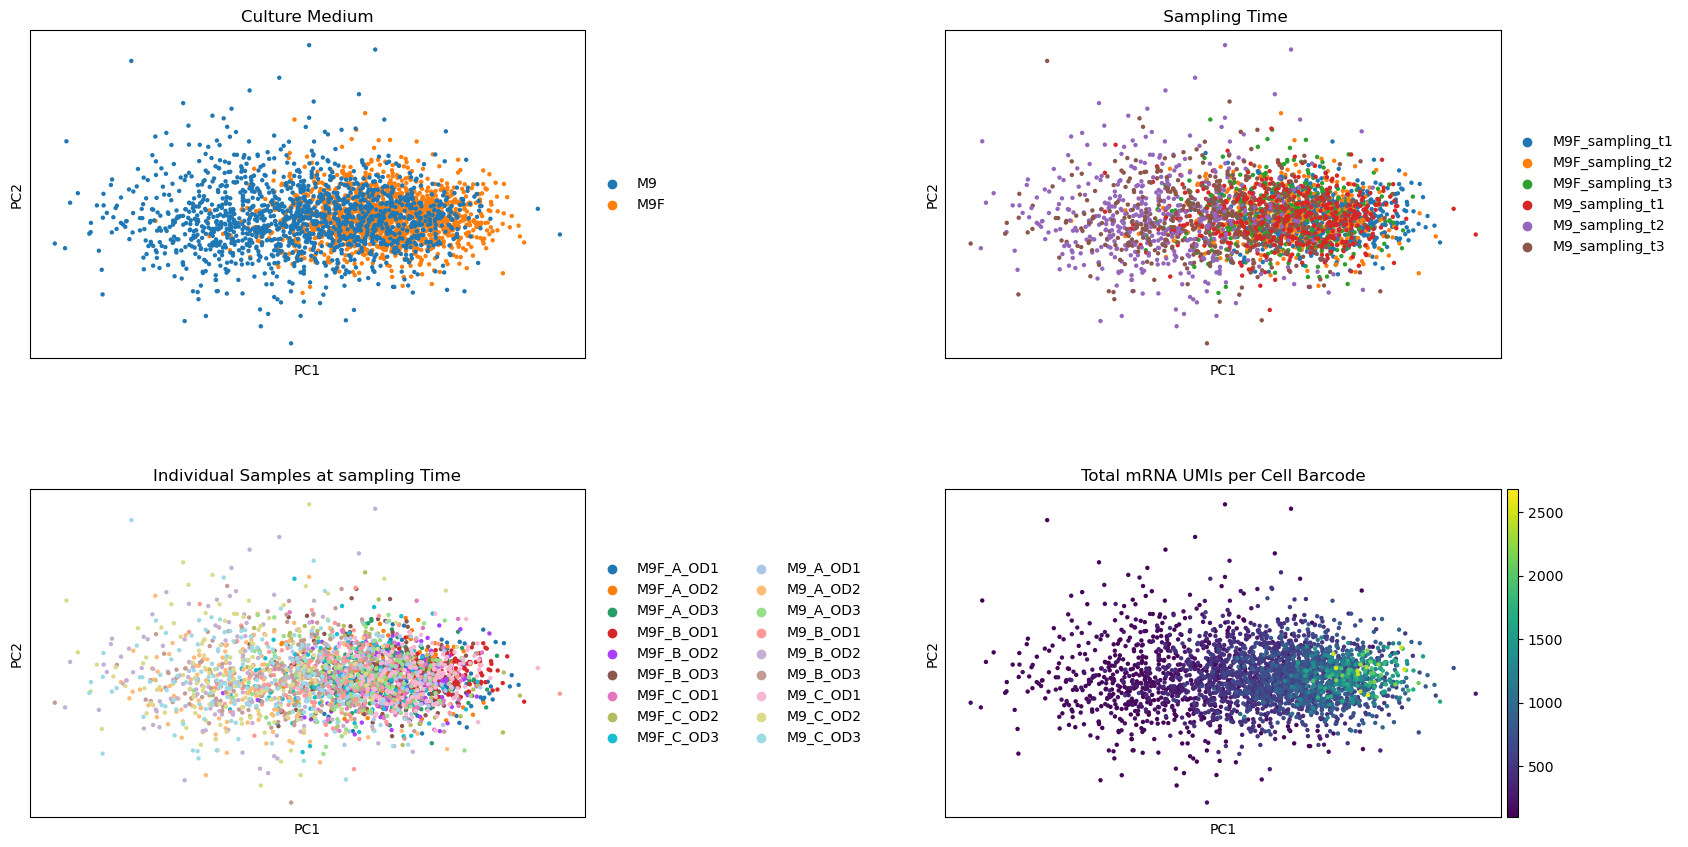

In [212]:
sc.pl.pca(
    adata,
    ncols=2,
    color=["CultureMedium", "group", "OD", "total_counts"],
    alpha=1,
    cmap="viridis",
    title=[
        "Culture Medium",
        " Sampling Time",
        "Individual Samples at sampling Time",
        "Total mRNA UMIs per Cell Barcode",
    ],
    wspace=0.5,  # Increase horizontal spacing between plots
    hspace=0.4,  # Increase vertical spacing between plots
)

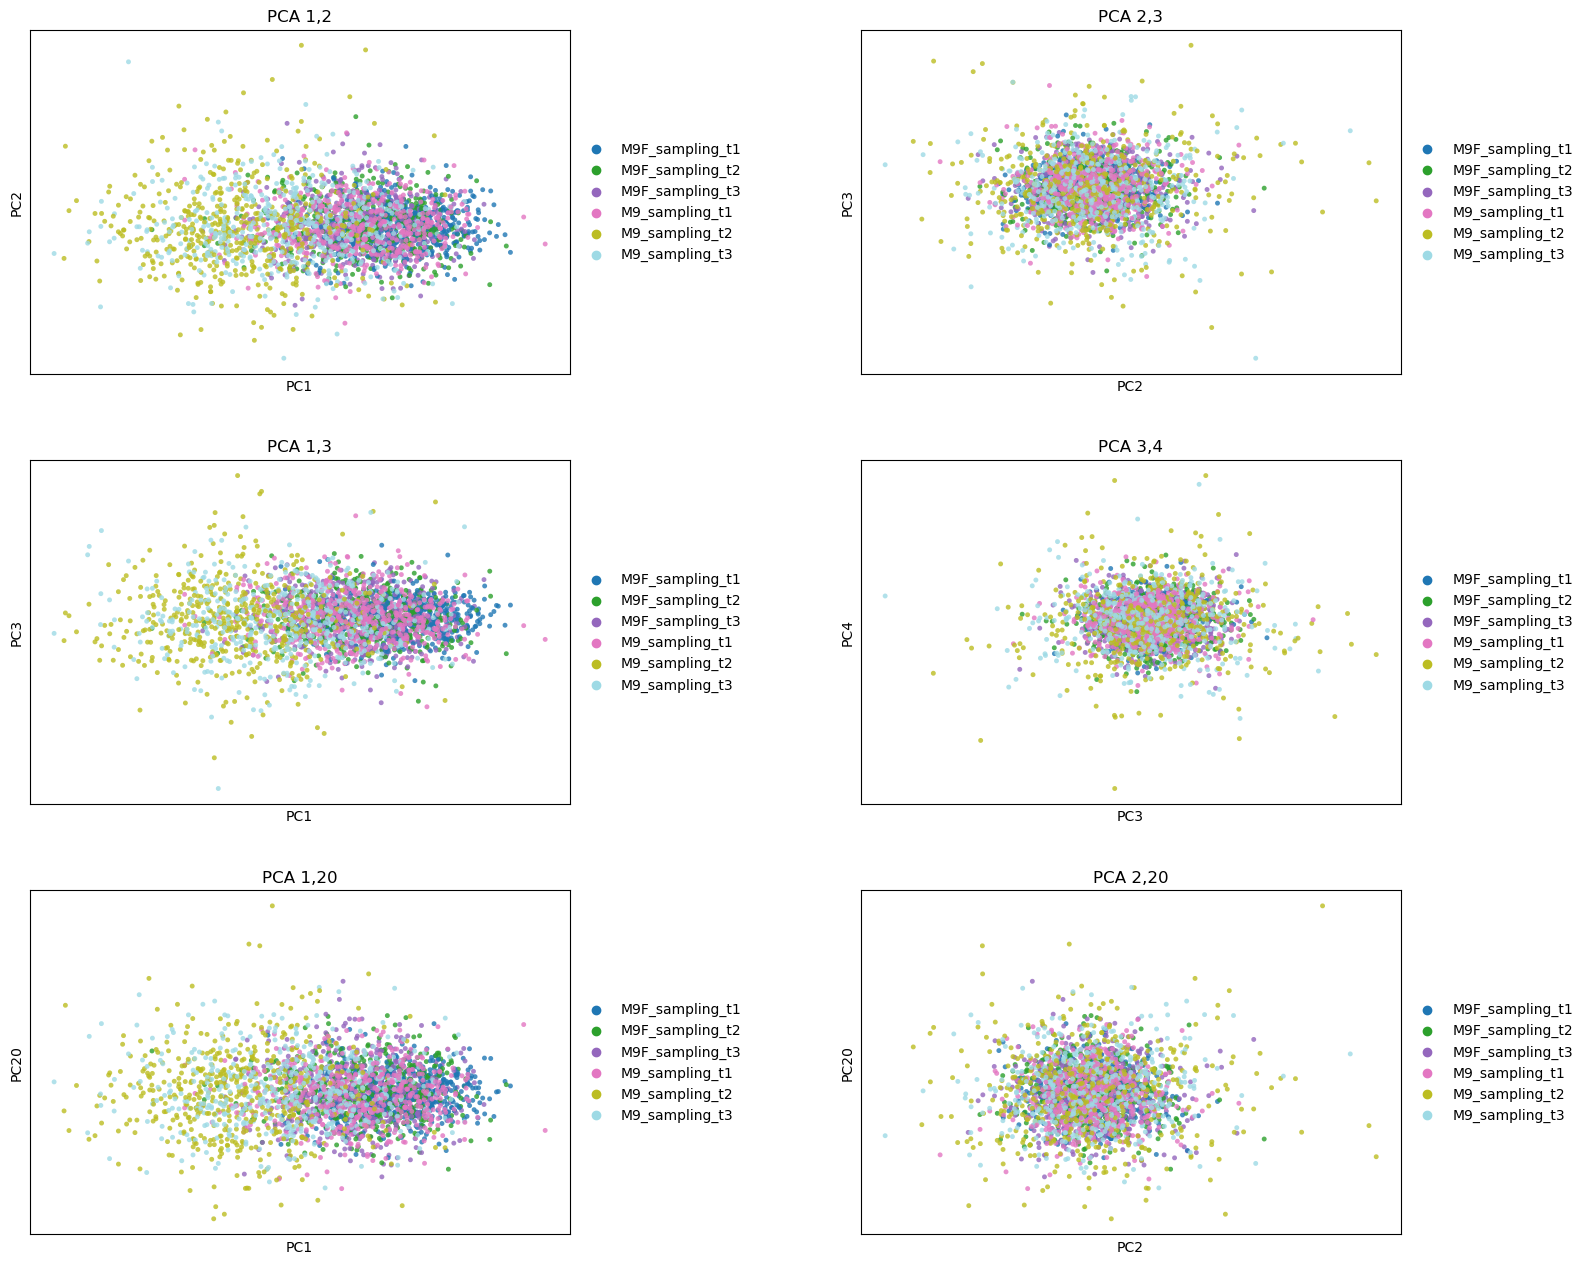

In [213]:
# Plot different PCA component combinations
sc.pl.pca(
    adata,
    components=["1,2", "2,3", "1,3", "3,4", "1,20", "2,20"],
    color=["group"],
    ncols=2,
    title=["PCA 1,2", "PCA 2,3", "PCA 1,3", "PCA 3,4", "PCA 1,20", "PCA 2,20"],
    palette="tab20",
    alpha=0.8,
    size=50,
    wspace=0.4,
)

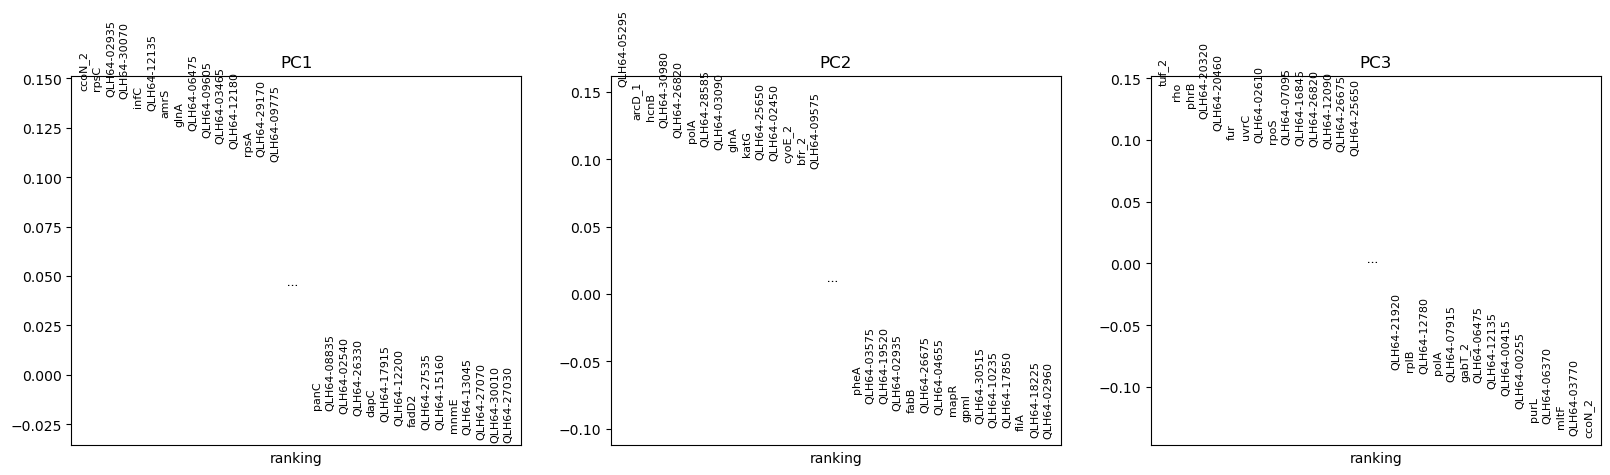

In [214]:
sc.pl.pca_loadings(adata, components=[1, 2, 3])

In [215]:
# Étape 1 : Obtenir les 20 gènes les plus positifs et négatifs des PCA 1,2 et les trier par importance
top_pos_pc1 = adata.varm["PCs"][:, 0].argsort()[-20:][
    ::-1
]  # 20 plus positifs PC1, triés par ordre décroissant
top_neg_pc1 = adata.varm["PCs"][:, 0].argsort()[
    :20
]  # 20 plus négatifs PC1, déjà triés par ordre croissant
top_pos_pc2 = adata.varm["PCs"][:, 1].argsort()[-20:][
    ::-1
]  # 20 plus positifs PC2, triés par ordre décroissant
top_neg_pc2 = adata.varm["PCs"][:, 1].argsort()[
    :20
]  # 20 plus négatifs PC2, déjà triés par ordre croissant

# Create DataFrames for each PC component with loading values
import pandas as pd


def create_gene_df(indices, pc_num, direction):
    loadings = adata.varm["PCs"][indices, pc_num - 1]  # Get actual loading values
    df = pd.DataFrame(
        {
            "final_gene_name": adata.var["final_gene_name"][indices],
            "Name": adata.var["Name"][indices],
            "loading_value": abs(loadings),  # Absolute loading value for sorting
            "n_cells_by_counts": adata.var["n_cells_by_counts"][indices],
            "mean_counts": adata.var["mean_counts"][indices],
            "total_counts": adata.var["total_counts"][indices],
            "PC": [f"PC{pc_num}"] * len(indices),
            "Direction": [direction] * len(indices),
        }
    )
    return df.sort_values(
        "loading_value", ascending=False
    )  # Sort by absolute loading value


# Create sorted DataFrames for each component
pc1_pos_df = create_gene_df(top_pos_pc1, 1, "positive")
pc1_neg_df = create_gene_df(top_neg_pc1, 1, "negative")
pc2_pos_df = create_gene_df(top_pos_pc2, 2, "positive")
pc2_neg_df = create_gene_df(top_neg_pc2, 2, "negative")

# Combine all DataFrames
all_genes_df = pd.concat([pc1_pos_df, pc1_neg_df, pc2_pos_df, pc2_neg_df])

# Sort the full table by PC and loading value
sorted_genes_df = all_genes_df.sort_values(
    ["PC", "loading_value"], ascending=[True, False]
)

# Print the sorted table
print(sorted_genes_df)

            final_gene_name  \
gene_name                     
ccoN_2               ccoN_2   
rpsC                   rpsC   
QLH64-02935     QLH64-02935   
QLH64-30070     QLH64-30070   
infC                   infC   
...                     ...   
QLH64-15580     QLH64-15580   
QLH64-11935     QLH64-11935   
murA                   murA   
pnp                     pnp   
fur                     fur   

                                                          Name  loading_value  \
gene_name                                                                       
ccoN_2               cytochrome-c oxidase, cbb3-type subunit I       0.144098   
rpsC                                  30S ribosomal protein S3       0.143866   
QLH64-02935                                 carbohydrate porin       0.141084   
QLH64-30070                     DNA cytosine methyltransferase       0.140103   
infC                        translation initiation factor IF-3       0.135469   
...                          

In [216]:
# Use these parameters if you don't want to run scDEED
n_neighbors_opt = 20
min_dist_opt = 0.3
n_pcs_opt = 5

In [217]:
sc.pp.neighbors(adata, n_neighbors=n_neighbors_opt, n_pcs=n_pcs_opt)
sc.tl.umap(
    adata,
    neighbors_key="neighbors",
    min_dist=min_dist_opt,
    spread=1,
    random_state=3456,
)

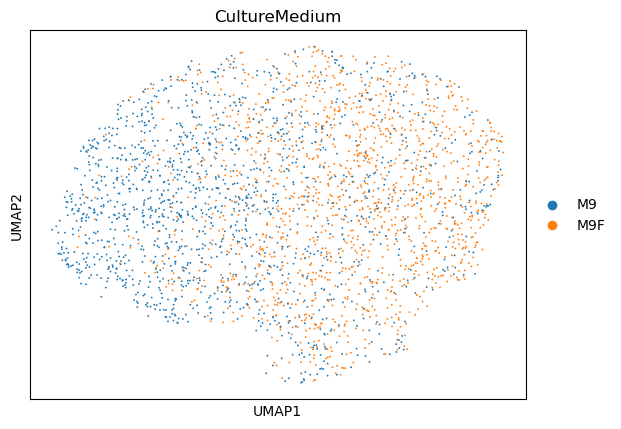

In [218]:
sc.pl.umap(
    adata,
    color="CultureMedium",
    # Setting a smaller point size to get prevent overlap
    size=7,
)

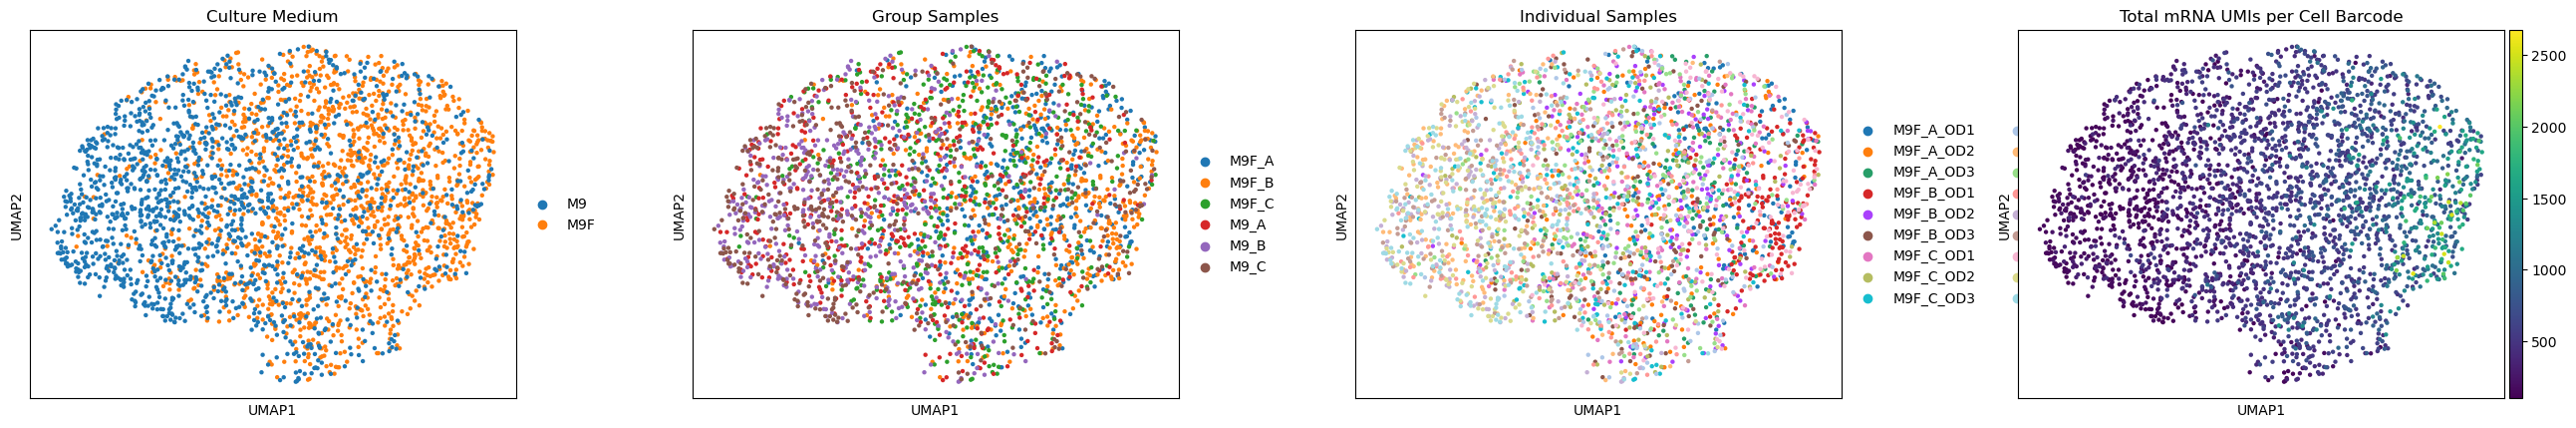

In [219]:
sc.pl.umap(
    adata,
    color=["CultureMedium", "RepBio", "OD", "total_counts"],
    alpha=1,
    cmap="viridis",
    title=[
        "Culture Medium",
        "Group Samples",
        "Individual Samples",
        "Total mRNA UMIs per Cell Barcode",
    ],
    wspace=0.24,  # Increase space between plots horizontally
    hspace=0.3,  # Increase space between plots vertically
)
plt.show()

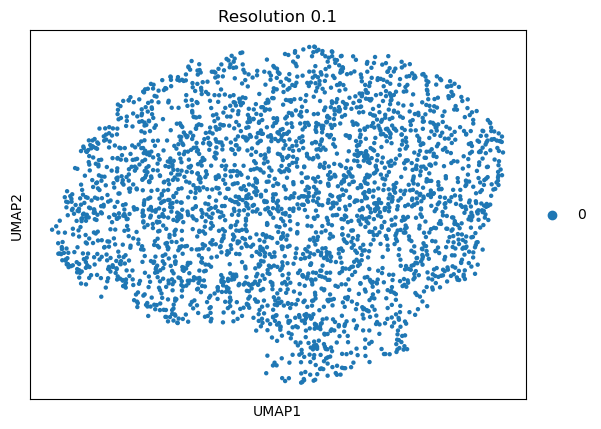

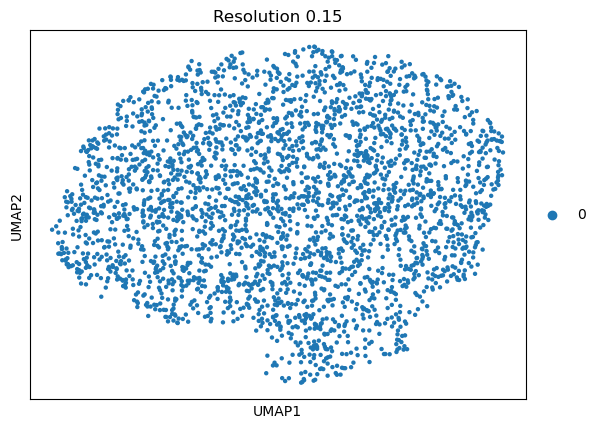

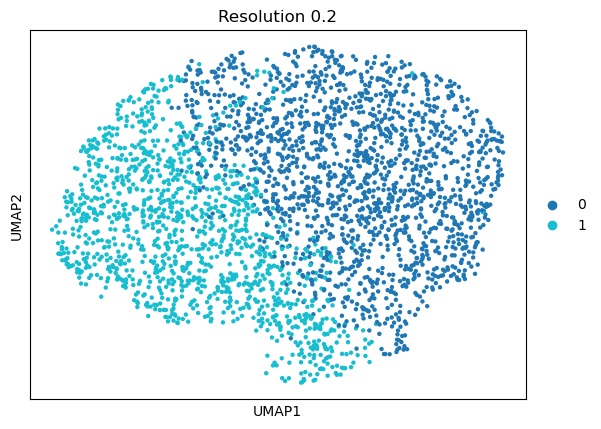

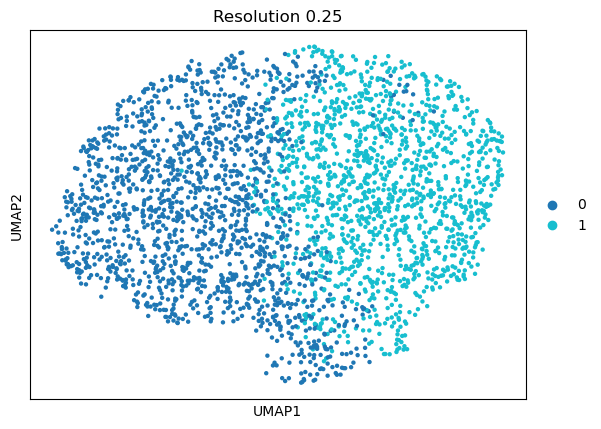

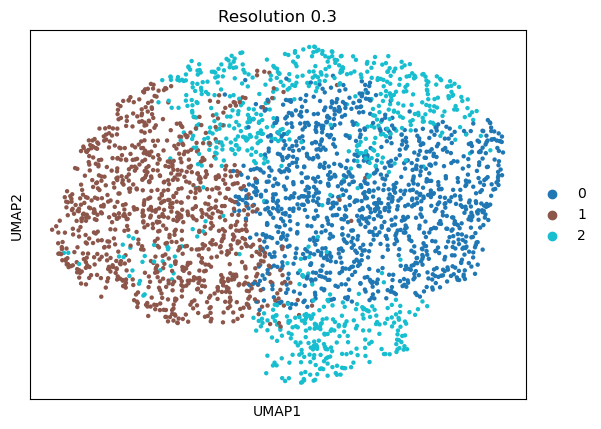

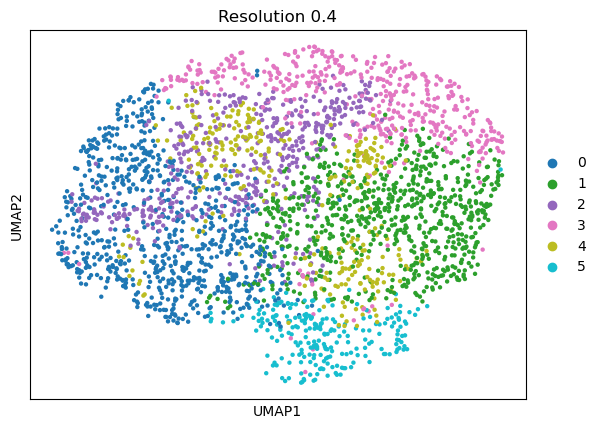

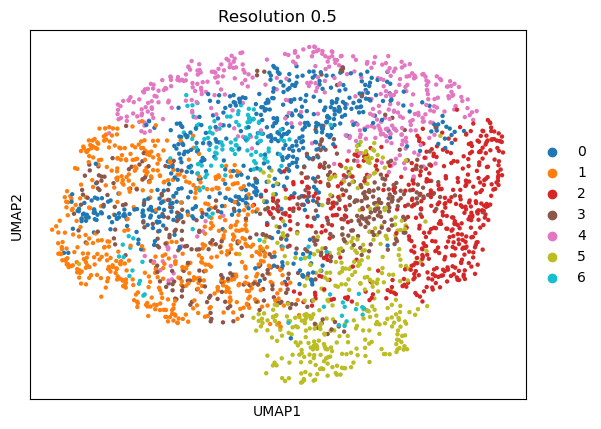

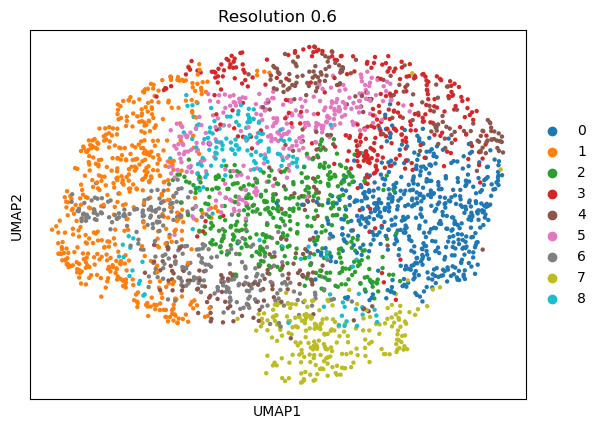

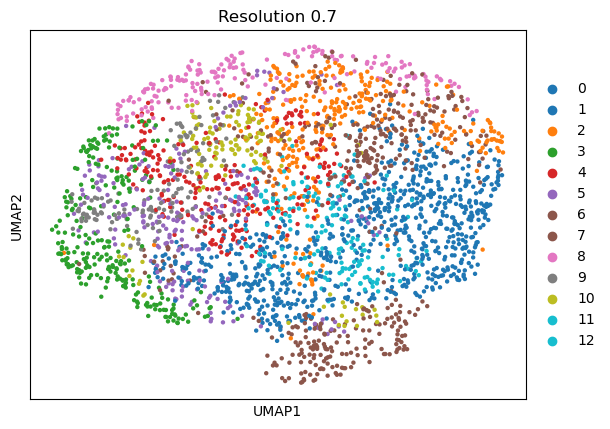

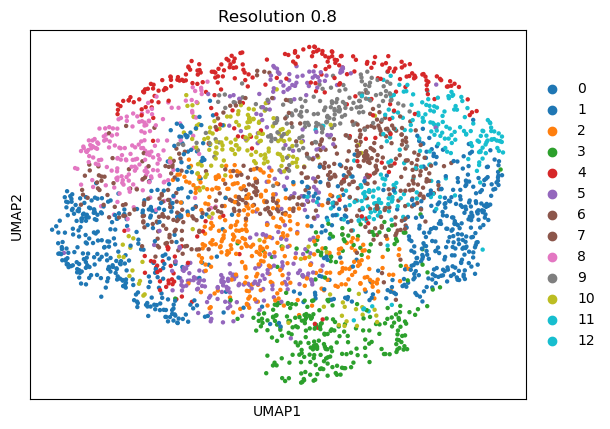

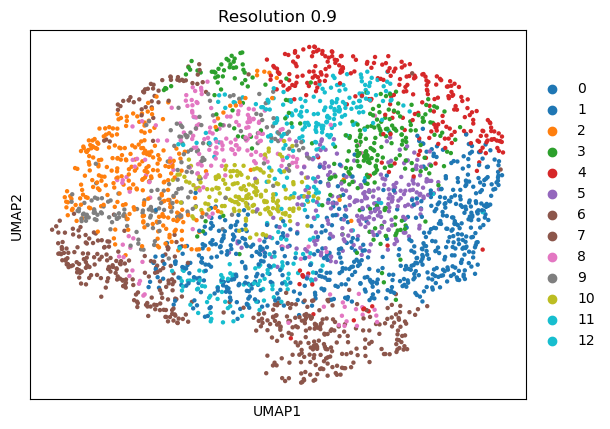

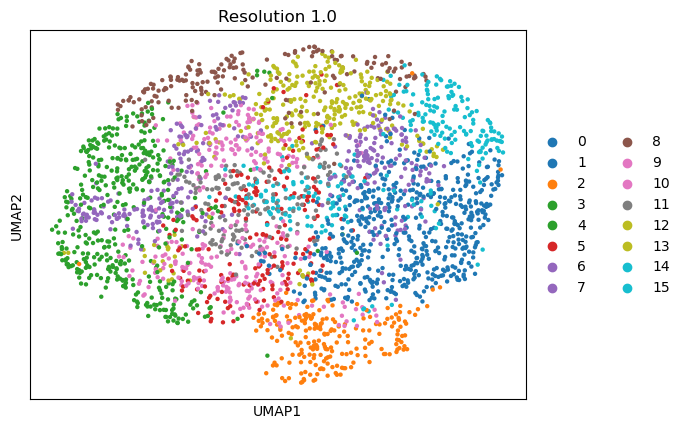

In [220]:
# create differente resolution for leiden clustering with for loop
for resolution in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    sc.tl.leiden(
        adata,
        resolution=resolution,
        key_added=f"leiden_opt_{resolution}",
        random_state=1234,
    )

# plot the differente resolution for leiden clustering with for loop
for resolution in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    sc.pl.umap(
        adata,
        color=f"leiden_opt_{resolution}",
        palette="tab10",
        title=f"Resolution {resolution}",
    )
    plt.show()

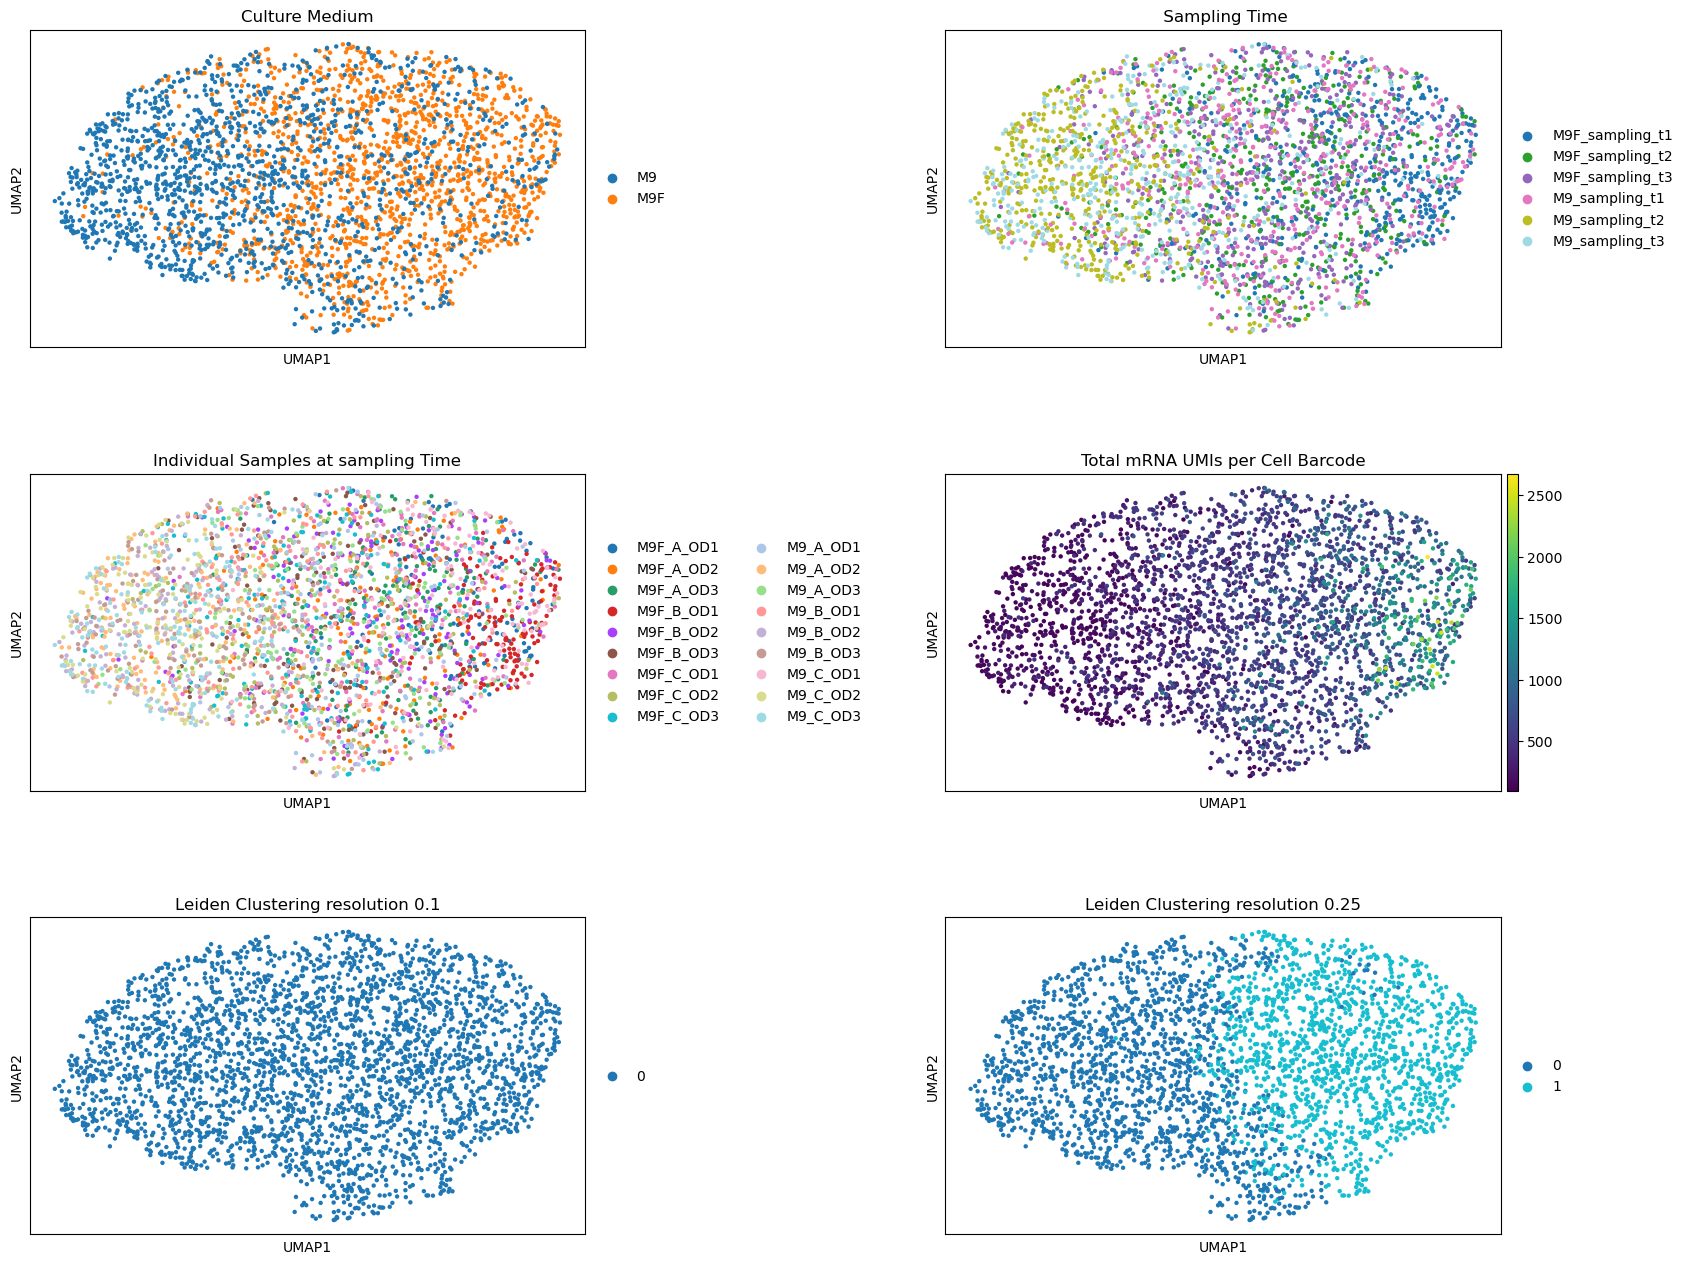

In [221]:
sc.pl.umap(
    adata,
    ncols=2,
    color=[
        "CultureMedium",
        "group",
        "OD",
        "total_counts",
        "leiden_opt_0.1",
        "leiden_opt_0.25",
    ],
    alpha=1,
    cmap="viridis",
    title=[
        "Culture Medium",
        " Sampling Time",
        "Individual Samples at sampling Time",
        "Total mRNA UMIs per Cell Barcode",
        "Leiden Clustering resolution 0.1",
        "Leiden Clustering resolution 0.25",
    ],
    wspace=0.5,  # Increase horizontal spacing between plots
    hspace=0.4,  # Increase vertical spacing between plots
)

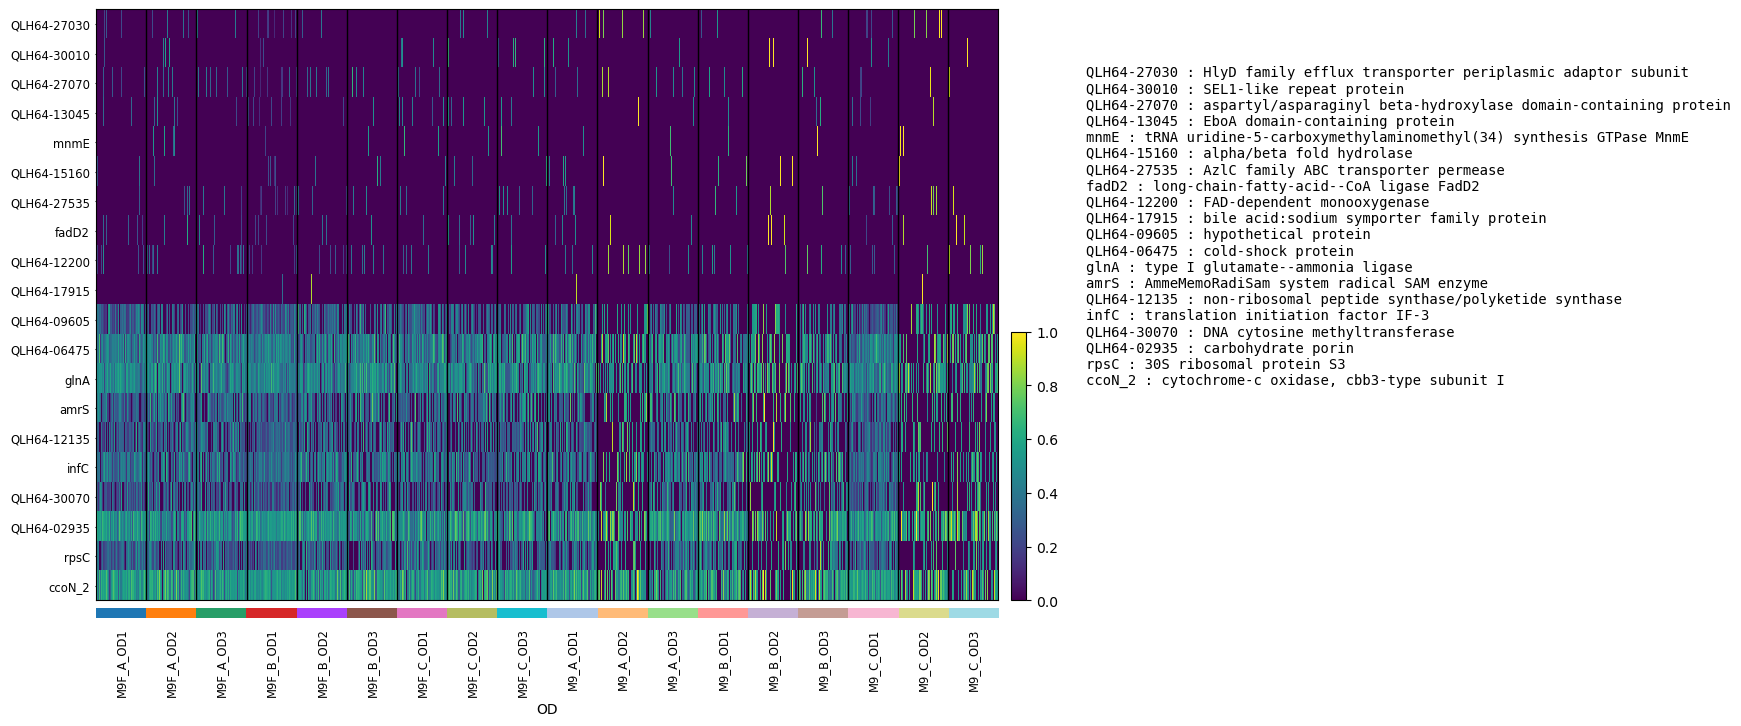

In [222]:
# Get PCA1 loadings and sort genes
pc1_loadings = adata.varm["PCs"][:, 0]  # PC1 loadings
sorted_idx = np.argsort(pc1_loadings)
selected_genes = adata.var_names[np.concatenate((sorted_idx[:10], sorted_idx[-10:]))]

# Sort cells by PC1 coordinates
pc1_coords = adata.obsm["X_pca"][:, 0]
ordered_cells = np.argsort(pc1_coords)
tempdata = adata[ordered_cells, :]

# 1. Display heatmap with Scanpy
sc.pl.heatmap(
    tempdata,
    var_names=selected_genes.tolist(),
    groupby="OD",
    swap_axes=True,
    use_raw=False,
    show=False,  # To modify with matplotlib
    figsize=(12, 8),
    dendrogram=False,
    standard_scale="var",
)

# 2. Add text on right side of figure
gene_names = dict(zip(adata.var_names, adata.var["Name"]))
legend_text = "\n".join([f"{gene} : {gene_names[gene]}" for gene in selected_genes])

# Get current figure
fig = plt.gcf()

# Add new area for text on right
ax_text = fig.add_axes([0.95, 0.2, 0.15, 0.6])  # Position more to right
ax_text.axis("off")  # No axes
ax_text.text(0, 1, legend_text, fontsize=10, va="top", family="monospace")

plt.show()

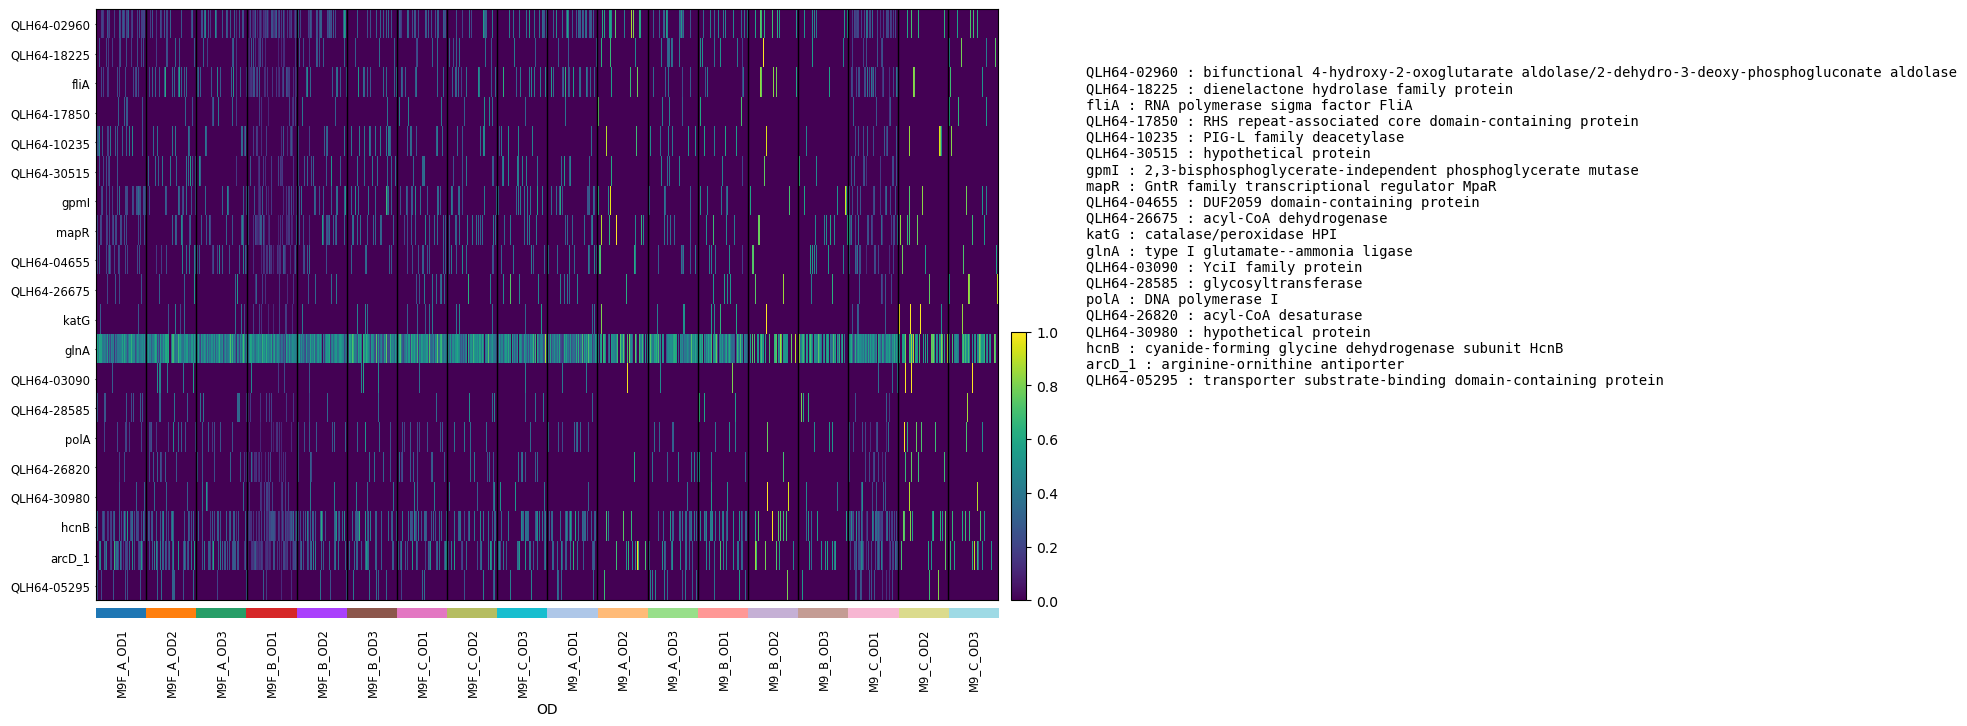

In [223]:
# Get PCA2 loadings and sort genes
pc2_loadings = adata.varm["PCs"][:, 1]  # PC2 loadings
sorted_idx = np.argsort(pc2_loadings)
selected_genes = adata.var_names[np.concatenate((sorted_idx[:10], sorted_idx[-10:]))]

# Sort cells by PC2 coordinates
pc2_coords = adata.obsm["X_pca"][:, 1]
ordered_cells = np.argsort(pc2_coords)
tempdata = adata[ordered_cells, :]

# 1. Display heatmap with Scanpy
sc.pl.heatmap(
    tempdata,
    var_names=selected_genes.tolist(),
    groupby="OD",
    swap_axes=True,
    use_raw=False,
    show=False,  # To modify with matplotlib
    figsize=(12, 8),
    dendrogram=False,
    standard_scale="var",
)

# 2. Add text on right side of figure
gene_names = dict(zip(adata.var_names, adata.var["Name"]))
legend_text = "\n".join([f"{gene} : {gene_names[gene]}" for gene in selected_genes])

# Get current figure
fig = plt.gcf()

# Add new area for text on right
ax_text = fig.add_axes([0.95, 0.2, 0.15, 0.6])  # Position more to right
ax_text.axis("off")  # No axes
ax_text.text(0, 1, legend_text, fontsize=10, va="top", family="monospace")

plt.show()